In [59]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as pe
import csv
import ast

In [60]:
CHANNELS = range(7)
SCALE = 40
PATH_BASE = "/home/sansone/multiPMTsim/multipmt-simulation/build/data"

In [61]:
radius = 2
angles = np.linspace(0, 2 * np.pi, 7)
x_positions = radius * np.cos(angles)
y_positions = radius * np.sin(angles)

In [62]:
def leggi_evento_csv(filename):
    all_energies = np.zeros(7)
    all_times = np.zeros(7)

    with open(filename, newline='') as csvfile:
        reader = csv.DictReader(csvfile)
        for row in reader:
            pmt_id = int(row['PmtID'])
            pe = float(row['Hits'])

            try:
                
                time_list = ast.literal_eval(row['TimeHits'])
                first_time = float(np.min(time_list)) if time_list else 0.0
            except (ValueError, SyntaxError):
                first_time = 0.0

            all_energies[pmt_id] = pe
            all_times[pmt_id] = first_time

    

    return np.array(all_energies), np.array(all_times)

In [81]:
def plot_evento(all_energies, all_times, x_positions, y_positions,
                SCALE=45, title="multiPMT Event", muon=True):
    
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.set_aspect('equal', adjustable='datalim')

    norm = mcolors.Normalize(vmin=0, vmax=1.6)
    colormap = plt.colormaps.get("autumn_r") if muon else plt.colormaps.get("autumn_r") #per i muoni era winter
    sm = ScalarMappable(cmap=colormap, norm=norm)

    no_zero_time = all_times[all_times > 0]

    text_effect = [pe.withStroke(linewidth=3, foreground='white')]
    text_offset = 0.12
    max_radius_for_outside_text = 0.5  # soglia per far entrare i testi dentro il cerchio
    inner_text_distance = 0.25  # distanza fissa dal centro per testo interno

    def get_text_position(y, radius):
        """Restituisce le coordinate y del testo sopra e sotto il cerchio"""
        if radius < max_radius_for_outside_text:
            return y + radius + text_offset, y - radius - text_offset  # sopra, sotto
        else:
            return y + inner_text_distance, y - inner_text_distance  # dentro, distanza fissa dal centro

    # --- PMT centrale ---
    center_energy = all_energies[0]
    center_time = all_times[0]
    if center_time > 0 and center_energy > 0:
        time_diff = center_time - np.min(no_zero_time)
        center_color = colormap(norm(time_diff))
        radius = (center_energy / SCALE) + 0.05
        label_pe = f"{round(center_energy)} pe"
        label_time = f"{round(time_diff, 3)} ns"
    else:
        center_color = "gray"
        radius = 0.05
        label_pe = ""
        label_time = ""

    # Cerchio centrale
    center_pmt = Circle((0, 0), radius, color=center_color,
                        linestyle="--" if center_energy == 0 else "-",
                        ec='k', lw=1)
    ax.add_patch(center_pmt)

    y_top, y_bottom = get_text_position(0, radius)
    if label_pe:
        ax.text(0, y_top, label_pe, ha='center', va='bottom',
                fontsize=20, color='black', path_effects=text_effect)
    if label_time:
        ax.text(0, y_bottom, label_time, ha='center', va='top',
                fontsize=20, color='black', path_effects=text_effect)

    # --- Altri PMT ---
    for i, (x, y) in enumerate(zip(x_positions, y_positions)):
        if i == 0:
            continue

        if all_times[i] > 0:
            time_diff = all_times[i] - np.min(no_zero_time)
            color = colormap(norm(time_diff))
            radius = (all_energies[i] / SCALE) + 0.05

            # Cerchio
            circle = Circle((x_positions[i-1], y_positions[i-1]), radius,
                            color=color, ec='k', lw=1)
            ax.add_patch(circle)

            # Testi: sopra e sotto, logica esterno/interno con distanza fissa dentro
            y_top, y_bottom = get_text_position(y_positions[i-1], radius)
            ax.text(x_positions[i-1], y_top, f"{round(all_energies[i])} pe",
                    ha='center', va='bottom', fontsize=20,
                    color='black', path_effects=text_effect)
            ax.text(x_positions[i-1], y_bottom, f"{round(time_diff, 3)} ns",
                    ha='center', va='top', fontsize=20,
                    color='black', path_effects=text_effect)

        else:
            circle = Circle((x_positions[i-1], y_positions[i-1]), 0.05,
                            color="gray", linestyle="--", ec='k', lw=0.8)
            ax.add_patch(circle)

    # --- Colorbar ---
    cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Time (ns)", fontsize=22)

    # --- Layout ---
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    ax.axvline(0, color='gray', linewidth=0.5, linestyle='--')
    ax.set_title(title, fontsize=22, pad=10)

    plt.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    plt.tight_layout()
    plt.show()

# Muon

In [82]:
file_mu_1_verticale_x_0_5_y_0_5 = PATH_BASE + "/2025-10-20/HitsData_PMT_vertical_mu_1_x_0_5_y_0_5.csv"

In [83]:
file_mu_1_inclined_bottom_x_1_y_1 = PATH_BASE + "/2025-10-20/HitsData_PMT_inclined_bottom_mu_1_x_1_y_1.csv"

In [84]:
file_mu_1_inclined_side_x_1_5_y_1_5 = PATH_BASE + "/2025-10-20/HitsData_PMT_inclined_side_mu_1_x_1_5_y_1_5.csv"

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


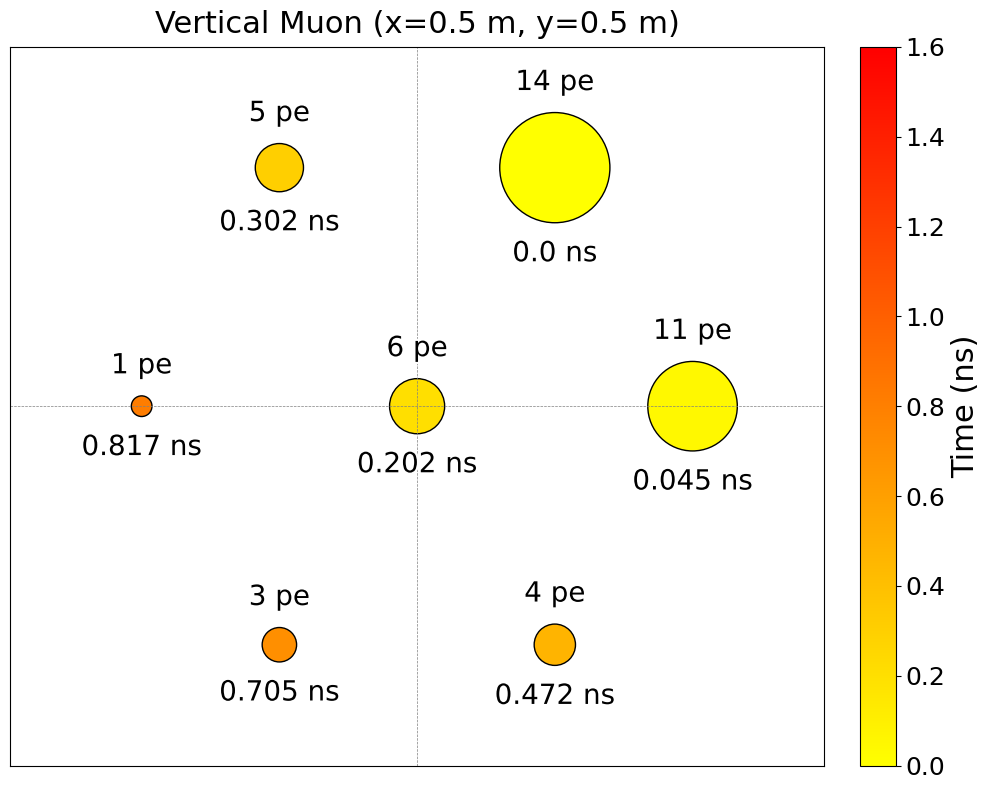

In [85]:
all_energies, all_time = leggi_evento_csv(file_mu_1_verticale_x_0_5_y_0_5)
plot_evento(all_energies, all_time, x_positions, y_positions, SCALE, title="Vertical Muon (x=0.5 m, y=0.5 m)")

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


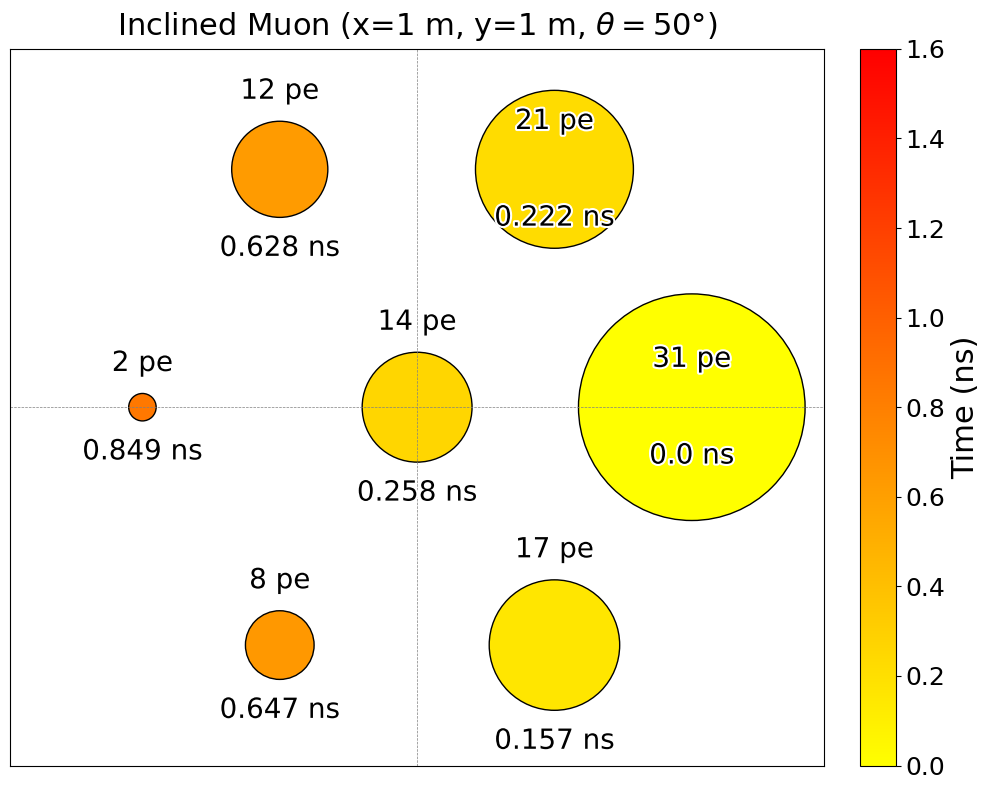

In [86]:
all_energies, all_time = leggi_evento_csv(file_mu_1_inclined_bottom_x_1_y_1)
plot_evento(all_energies, all_time, x_positions, y_positions, SCALE, title="Inclined Muon (x=1 m, y=1 m, $\\theta=50$°)")

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


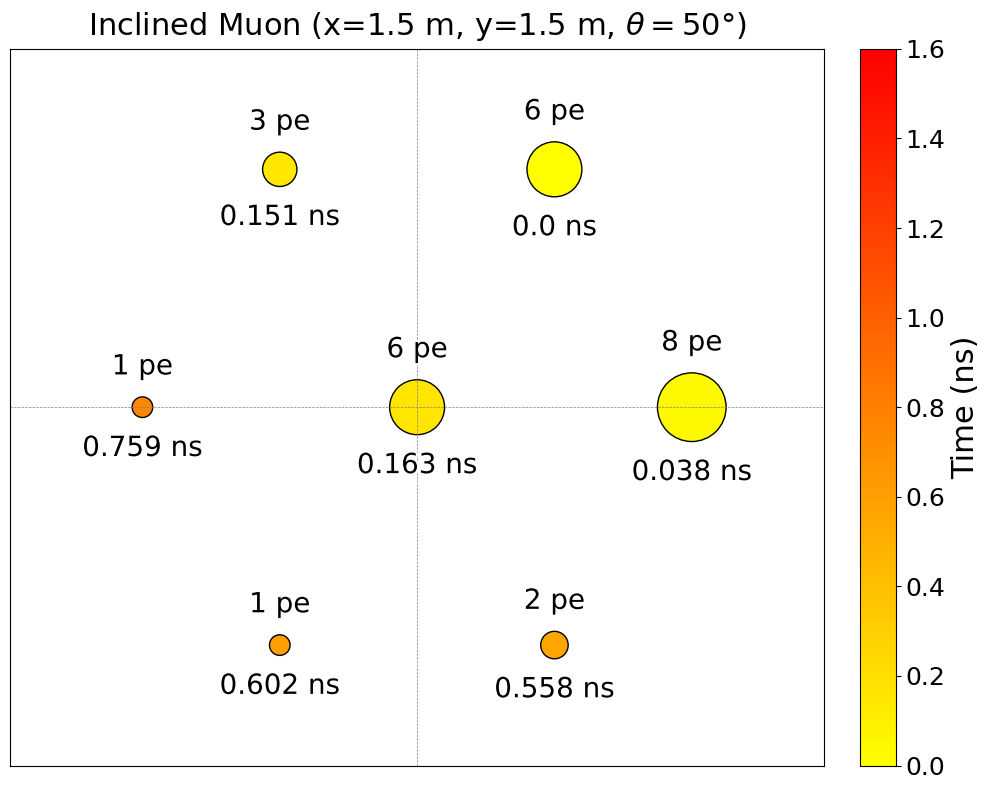

In [ ]:
all_energies, all_time = leggi_evento_csv(file_mu_1_inclined_side_x_1_5_y_1_5)
plot_evento(all_energies, all_time, x_positions, y_positions, SCALE, title="Inclined Muon (x=1.5 m, y=1.5 m, $\\theta=70$°)")

# Gamma

In [91]:
file_gamma_1_verticale_x_0_5_y_0_5 = PATH_BASE + "/2025-10-20/HitsData_PMT_vertical_gamma_1_x_0_5_y_0_5.csv"

In [92]:
file_gamma_1_inclined_bottom_x_1_y_1 = PATH_BASE + "/2025-10-20/HitsData_PMT_inclined_bottom_gamma_1_x_1_y_1.csv"

In [93]:
file_gamma_1_inclined_side_x_1_5_y_1_5 = PATH_BASE + "/2025-10-20/HitsData_PMT_inclined_side_gamma_1_x_1_5_y_1_5.csv"

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


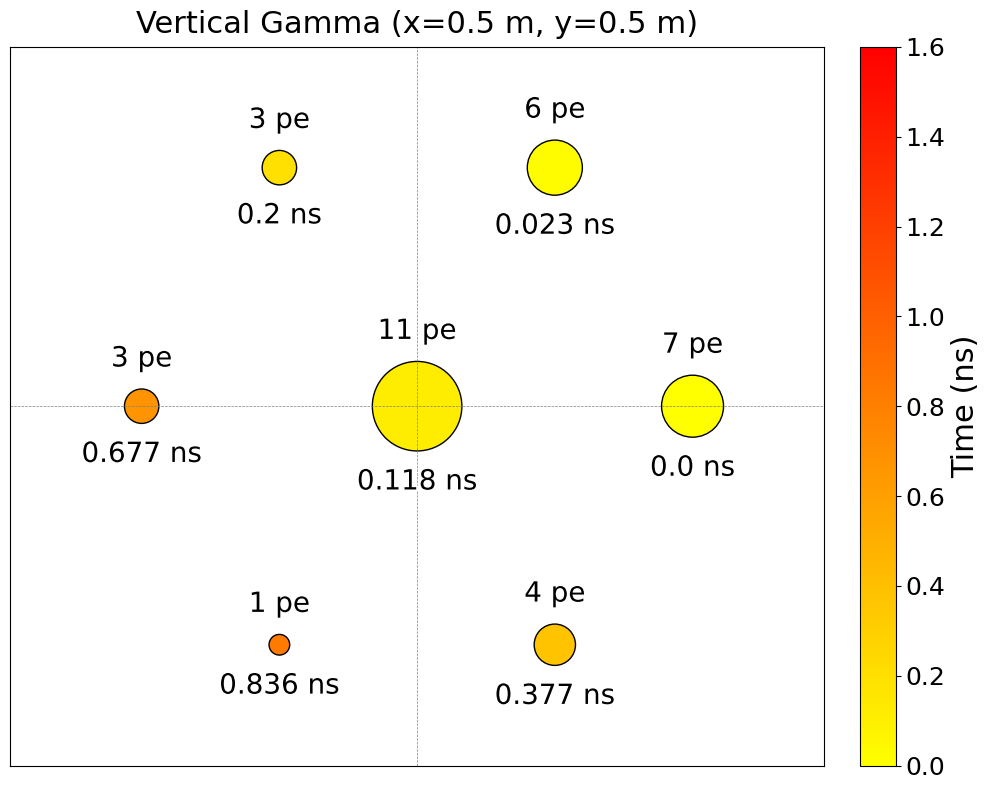

In [94]:
all_energies, all_time = leggi_evento_csv(file_gamma_1_verticale_x_0_5_y_0_5)
plot_evento(all_energies, all_time, x_positions, y_positions, SCALE, title="Vertical Gamma (x=0.5 m, y=0.5 m)")

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


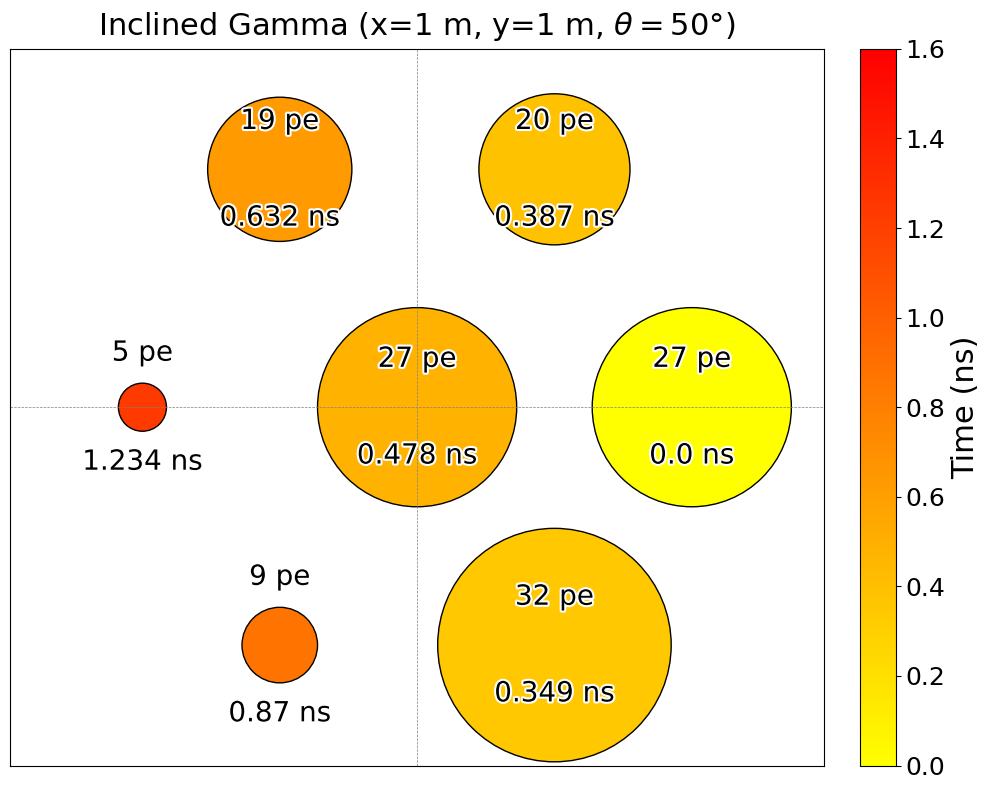

In [95]:
all_energies, all_time = leggi_evento_csv(file_gamma_1_inclined_bottom_x_1_y_1)
plot_evento(all_energies, all_time, x_positions, y_positions, SCALE, title="Inclined Gamma (x=1 m, y=1 m, $\\theta=50$°)")

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


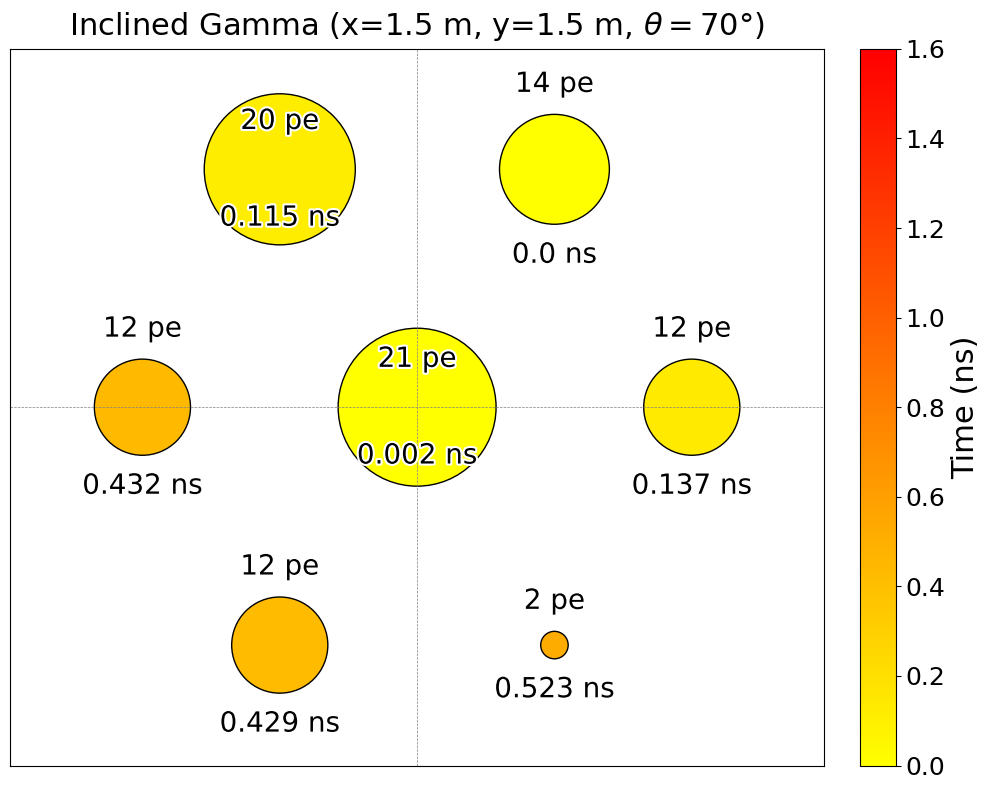

In [96]:
all_energies, all_time = leggi_evento_csv(file_gamma_1_inclined_side_x_1_5_y_1_5)
plot_evento(all_energies, all_time, x_positions, y_positions, SCALE, title="Inclined Gamma (x=1.5 m, y=1.5 m, $\\theta=70$°)")

# Electron

In [97]:
file_e_1_verticale_x_0_5_y_0_5 = PATH_BASE + "/2025-10-21/HitsData_PMT_vertical_e_1_x_0_5_y_0_5.csv"

In [98]:
file_e_1_inclined_bottom_x_1_y_1 = PATH_BASE + "/2025-10-21/HitsData_PMT_inclined_bottom_e_1_x_1_y_1.csv"

In [99]:
file_e_1_inclined_side_x_1_5_y_1_5 = PATH_BASE + "/2025-10-21/HitsData_PMT_inclined_side_e_1_x_1_5_y_1_5.csv"

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


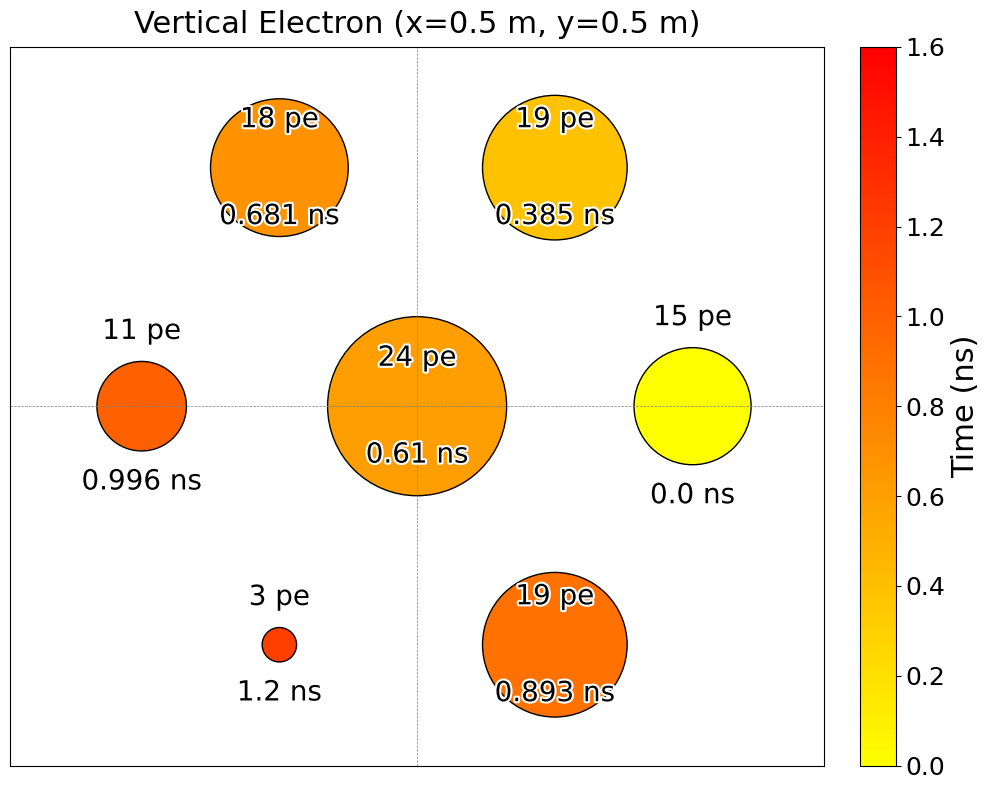

In [100]:
all_energies, all_time = leggi_evento_csv(file_e_1_verticale_x_0_5_y_0_5)
plot_evento(all_energies, all_time, x_positions, y_positions, SCALE, title="Vertical Electron (x=0.5 m, y=0.5 m)")

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


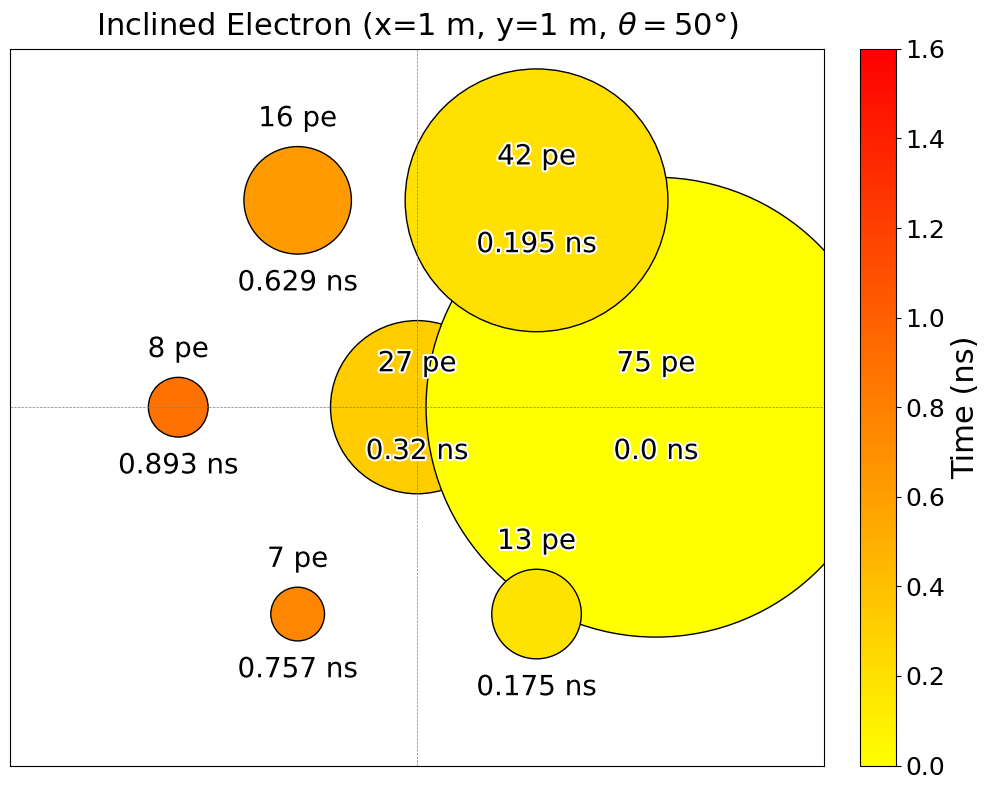

In [101]:
all_energies, all_time = leggi_evento_csv(file_e_1_inclined_bottom_x_1_y_1)
plot_evento(all_energies, all_time, x_positions, y_positions, SCALE, title="Inclined Electron (x=1 m, y=1 m, $\\theta=50$°)")

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


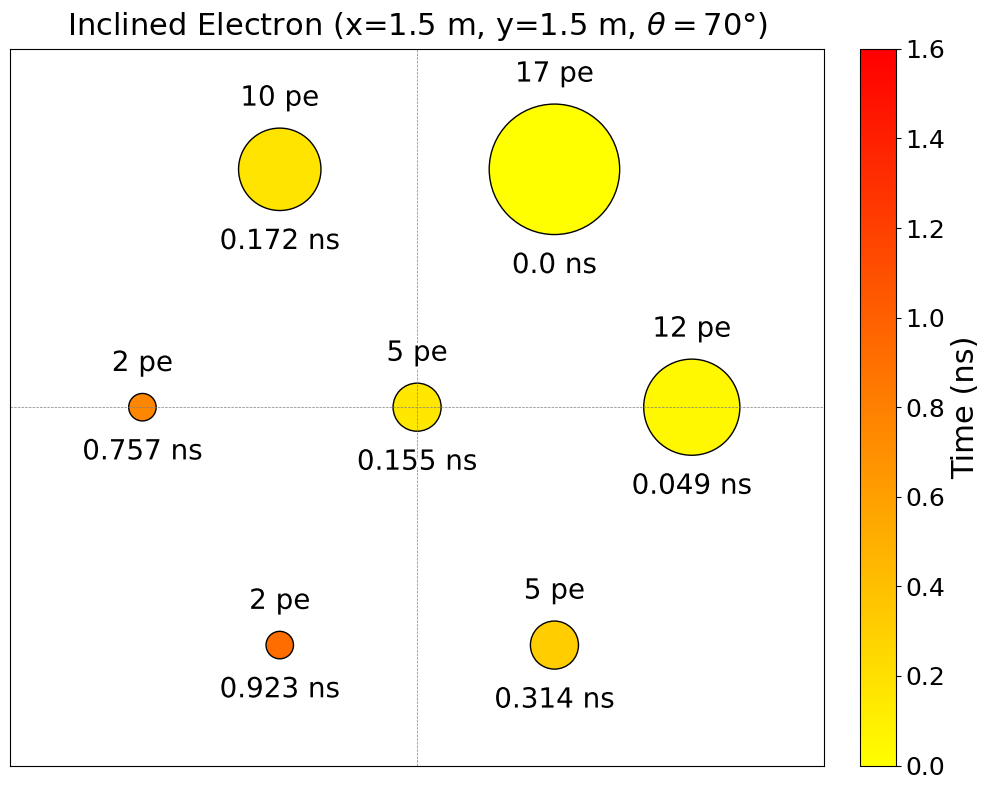

In [102]:
all_energies, all_time = leggi_evento_csv(file_e_1_inclined_side_x_1_5_y_1_5)
plot_evento(all_energies, all_time, x_positions, y_positions, SCALE, title="Inclined Electron (x=1.5 m, y=1.5 m, $\\theta=70$°)")

# Diagonal

In [103]:
file_mu_1_diagonale = PATH_BASE + "/2025-10-21/HitsData_PMT_mu_diagonal.csv"

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


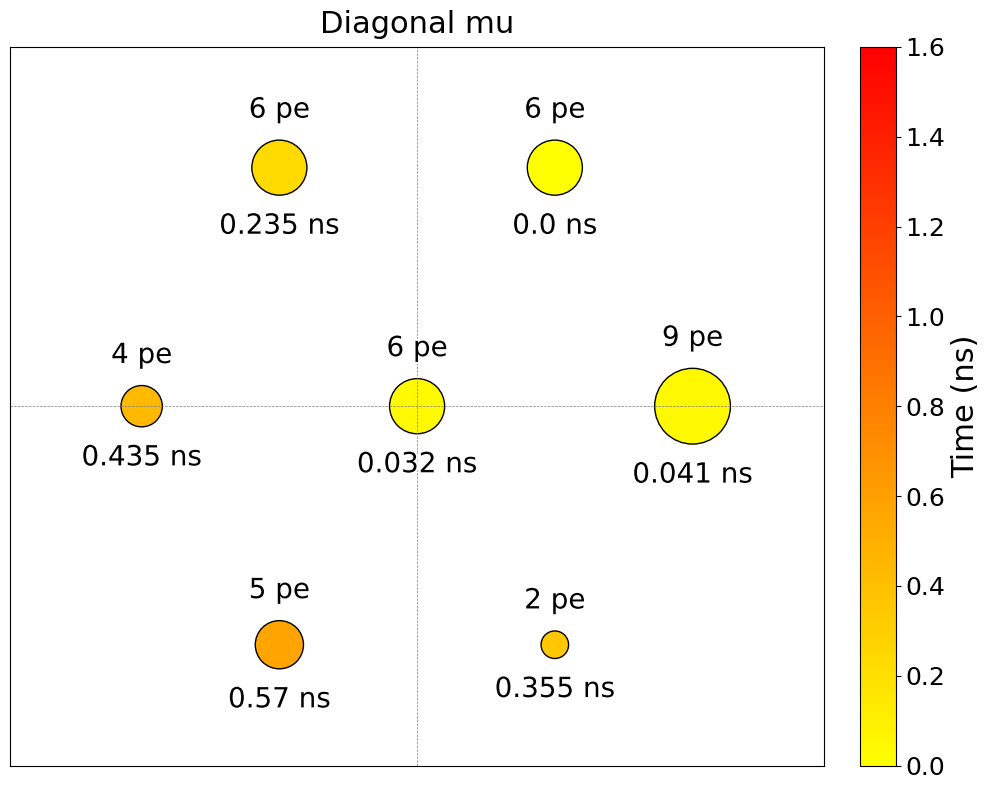

In [104]:
all_energies, all_time = leggi_evento_csv(file_mu_1_diagonale)
plot_evento(all_energies, all_time, x_positions, y_positions, SCALE, title="Diagonal mu")

In [105]:
file_gamma_1_diagonale = PATH_BASE + "/2025-10-21/HitsData_PMT_gamma_diagonal.csv"

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


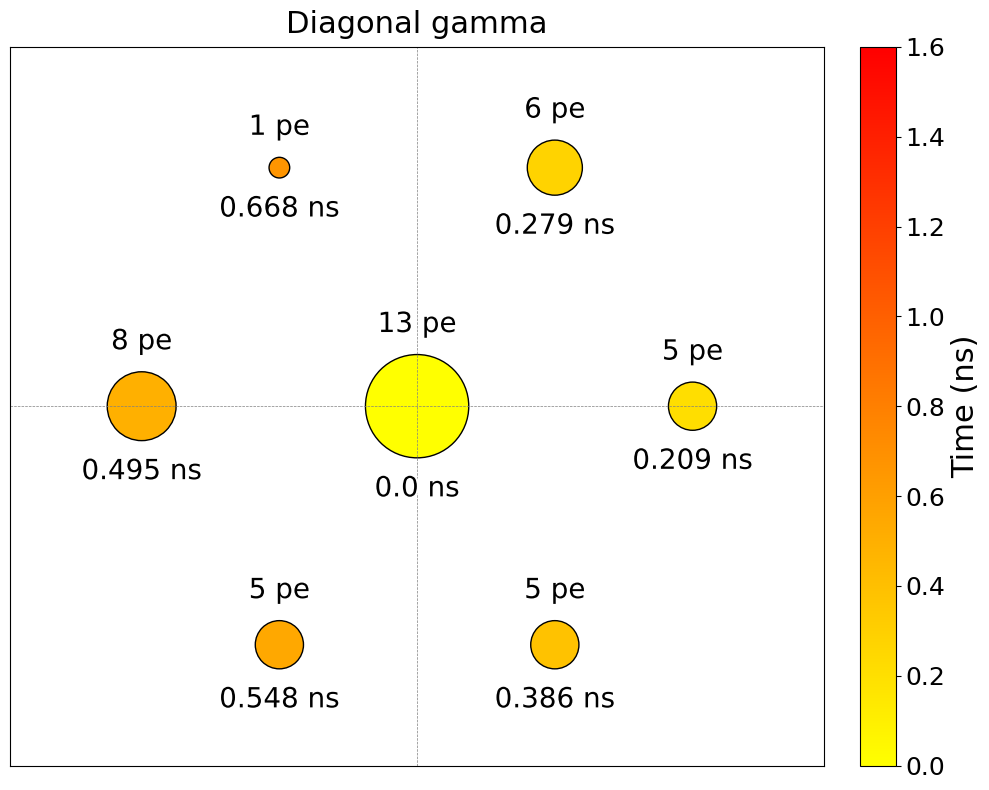

In [106]:
all_energies, all_time = leggi_evento_csv(file_gamma_1_diagonale)
plot_evento(all_energies, all_time, x_positions, y_positions, SCALE, title="Diagonal gamma")